# Steam 中文玩家體驗分析｜v0.2

研究：2026/08/01–2026/10/31（台灣時間），Overwatch 500、Apex Legends 500、鳴潮 300、燕雲十六聲 300。

本 Notebook 保留分析程式、表格、圖與結果。所有主題／情緒數字皆源自既有 AI 初判；本次抽查也是 AI 助理閱讀，**不是人工驗證**。原始檔不覆寫，人工確認欄留白。鳴潮「內容與養成」有反覆誤分類，不能直接以原排名解釋內容痛點。

在 Colab 選「執行全部」，上傳指定 CSV；Notebook 不需要 Steam、Google Drive 憑證或線上收集。若要保存回 Google Drive，請自行另存 Notebook；此處不會同步或發布 GitHub。

## 1. 執行環境

固定統計與繪圖套件版本。Colab 若無中文字型，圖表使用英文主題名稱，中文報告與資料不變。

In [1]:
import sys, subprocess, os
from pathlib import Path
os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.matplotlib-cache'))
os.environ.setdefault('IPYTHONDIR', str(Path.cwd() / '.ipython-cache'))
subprocess.run([sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check',
                '--quiet', 'pandas==3.1.1', 'matplotlib==3.11.2'], check=True)


CompletedProcess(args=['/workspace/.steam-environment/venv/bin/python', '-m', 'pip', 'install', '--disable-pip-version-check', '--quiet', 'pandas==3.1.1', 'matplotlib==3.11.2'], returncode=0)

## 2. 選擇資料檔

預設讀取同目錄的 `steam_chinese_1600_semantic_v02.csv`。同內容但其他檔名可修改 INPUT_PATH；Colab 找不到檔案時會跳出上傳。以 SHA-256 防止將既有抽查註記套到另一份資料。

In [2]:
from pathlib import Path
import hashlib
INPUT_PATH = ""  # 可填相同內容 CSV 的路徑
candidate = Path(INPUT_PATH) if INPUT_PATH else Path('steam_chinese_1600_semantic_v02.csv')
if not candidate.is_file():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('請將 CSV 放在目前目錄，或填寫 INPUT_PATH。')
    uploaded = files.upload()
    csv_names = [name for name in uploaded if name.lower().endswith('.csv')]
    if len(csv_names) != 1:
        raise ValueError('請一次上傳一份 CSV。')
    candidate = Path(csv_names[0])
expected_sha = '05cfe2fda17b17fcabc18d71d686fba53058ac9906f94b1a9ade3a34e142e088'
assert hashlib.sha256(candidate.read_bytes()).hexdigest() == expected_sha, (
    '檔案內容與此版不同。請先核對資料版本並重新抽樣／檢視抽查註記，避免沿用舊結論。')
OUTPUT = Path('results')
OUTPUT.mkdir(exist_ok=True)
print('資料版本 SHA-256 核對通過；輸出：', OUTPUT.resolve())


資料版本 SHA-256 核對通過；輸出： /workspace/steam_analysis_v02/results


## 3. 分析函式與助理抽查註記

以下完整內嵌程式與 34 筆註記，無須另外上傳 Python 或 JSON。註記是本版既有抽查觀察，不會在重跑時呼叫 AI；使用者應在匯出的人工欄位另行確認。

In [3]:
from pathlib import Path
import hashlib
import json
import platform
import sys
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager

GAMES = ['Overwatch', 'Apex Legends', '鳴潮', '燕雲十六聲']
EXPECTED = {'Overwatch': 500, 'Apex Legends': 500, '鳴潮': 300, '燕雲十六聲': 300}
APPIDS = {'Overwatch': '2357570', 'Apex Legends': '1172470', '鳴潮': '3513350', '燕雲十六聲': '3564740'}
ATTITUDES = ['批評', '肯定', '混合', '中性提及', '不確定']

def validate_and_expand(path, output):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    df = pd.read_csv(path, dtype={'review_id': 'string', 'appid': 'string'})
    required = ['game','appid','review_id','review','language','requested_language',
                'timestamp_created','timestamp_updated','created_at_utc','month',
                '文字情緒_AI','主題_AI','各主題態度_AI','分析適用性_AI','研究期後更新',
                '人工驗證狀態','人工確認情緒','人工確認主題態度','人工複核備註']
    absent = sorted(set(required) - set(df.columns))
    if absent:
        raise ValueError(f'缺少必要欄位：{absent}')
    core = [c for c in required if not c.startswith('人工確認') and c != '人工複核備註']
    blank = {c: int((df[c].isna() | df[c].astype('string').str.strip().eq('')).sum()) for c in core}
    if any(blank.values()):
        raise ValueError(f'必要欄位缺漏：{blank}')
    counts = df.groupby('game').size().to_dict()
    assert counts == EXPECTED, f'樣本配額不符：{counts}'
    assert not df.duplicated(['appid','review_id']).any(), '遊戲＋評論 ID 重複'
    assert df.review_id.is_unique, '全檔評論 ID 重複'
    assert df.review_id.str.fullmatch(r'\d+').all()
    assert df.appid.eq(df.game.map(APPIDS)).all(), '遊戲 ID 不符'
    assert df.language.isin(['tchinese','schinese']).all()
    assert df.requested_language.isin(['tchinese','schinese']).all()
    created = pd.to_datetime(df.timestamp_created, unit='s', utc=True).dt.tz_convert('Asia/Taipei')
    updated = pd.to_datetime(df.timestamp_updated, unit='s', utc=True).dt.tz_convert('Asia/Taipei')
    start, end = pd.Timestamp('2026-08-01', tz='Asia/Taipei'), pd.Timestamp('2026-11-01', tz='Asia/Taipei')
    assert ((created >= start) & (created < end)).all(), '建立日期超出研究期間'
    assert (created.dt.strftime('%Y-%m') == df.month).all(), '月份欄與台灣時間不符'
    assert (pd.to_datetime(df.created_at_utc, utc=True) == created).all(), '日期欄不一致'
    assert (updated >= created).all(), '更新時間早於建立時間'
    after = updated >= end
    supplied_flag = df['研究期後更新'].astype(str).str.lower().map({'true':True,'false':False})
    assert supplied_flag.notna().all() and supplied_flag.eq(after).all(), '期後更新標記不一致'
    rows, duplicate_pairs = [], 0
    for _, r in df.iterrows():
        themes = {x.strip() for x in r['主題_AI'].split('；')} - {'無具體主題'}
        seen = {}
        for item in r['各主題態度_AI'].split('；'):
            item = item.strip()
            if item == '無具體主題':
                continue
            if '：' not in item:
                raise ValueError(f'態度格式錯誤：{r.review_id}: {item}')
            topic, attitude = [x.strip() for x in item.rsplit('：', 1)]
            assert attitude in ATTITUDES, f'未知態度：{attitude}'
            if topic in seen:
                assert seen[topic] == attitude, f'同評論同主題態度衝突：{r.review_id}'
                duplicate_pairs += 1
                continue
            seen[topic] = attitude
            rows.append({'game':r.game,'appid':r.appid,'review_id':r.review_id,
                         'topic':topic,'attitude_AI':attitude,'研究期後更新':bool(after.loc[r.name])})
        assert set(seen) == themes, f'主題及態度欄不一致：{r.review_id}'
    long = pd.DataFrame(rows)
    assert not long.duplicated(['appid','review_id','topic']).any()
    long.to_csv(output/'review_topic_long.csv', index=False, encoding='utf-8-sig')
    report = {
        'input_file': Path(path).name, 'sha256':hashlib.sha256(Path(path).read_bytes()).hexdigest(),
        'rows':len(df),'columns':len(df.columns),'game_counts':counts,
        'duplicate_review_ids':int(df.review_id.duplicated().sum()),
        'duplicate_game_review_ids':int(df.duplicated(['appid','review_id']).sum()),
        'duplicate_game_text_rows':int(df.duplicated(['game','review']).sum()),
        'note_duplicate_text':'同文不同 ID 保留，不視為同一評論；未驗證來源真實性或帳號獨立性。',
        'required_missing':blank,'created_min_taipei':str(created.min()),'created_max_taipei':str(created.max()),
        'post_period_updated':int(after.sum()),'post_period_updated_by_game':df.assign(after=after).groupby('game').after.sum().to_dict(),
        'topic_pair_rows':len(long),'duplicate_topic_pairs_removed':duplicate_pairs,
        'AI_applicability':df['分析適用性_AI'].value_counts().to_dict(),
        'human_review_status':df['人工驗證狀態'].value_counts().to_dict(),
        'no_topic_reviews':int(df['主題_AI'].eq('無具體主題').sum()),
        'python_version':platform.python_version(),'pandas_version':pd.__version__,'matplotlib_version':matplotlib.__version__,
        'denominator':'各遊戲全部樣本；不依分析適用性或情緒篩選。批評只計態度=批評，混合另列。',
    }
    (output/'validation.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
    df.groupby(['game','language','month']).size().rename('n').reset_index().to_csv(output/'sample_composition.csv',index=False,encoding='utf-8-sig')
    return df, long, report

def summarize(df, long, output):
    output = Path(output)
    stats = long.groupby(['game','topic','attitude_AI']).size().unstack(fill_value=0).reindex(columns=ATTITUDES,fill_value=0).reset_index()
    stats['sample_n'] = stats.game.map(EXPECTED)
    for a in ATTITUDES:
        stats[a+'_pct'] = stats[a] / stats.sample_n * 100
    stats.to_csv(output/'topic_statistics_AI.csv',index=False,encoding='utf-8-sig')
    ordered = stats.sort_values(['game','批評','topic'],ascending=[True,False,True])
    top5 = ordered.groupby('game',sort=False).head(5)
    top5.to_csv(output/'top5_criticism_AI.csv',index=False,encoding='utf-8-sig')
    positive = stats.sort_values(['game','肯定','topic'],ascending=[True,False,True]).groupby('game',sort=False).head(5)
    positive.to_csv(output/'top5_praise_AI.csv',index=False,encoding='utf-8-sig')
    emotions = df.groupby(['game','文字情緒_AI']).size().rename('n').reset_index()
    emotions['sample_n'] = emotions.game.map(EXPECTED)
    emotions['pct'] = emotions.n/emotions.sample_n*100
    emotions.to_csv(output/'emotion_statistics_AI.csv',index=False,encoding='utf-8-sig')
    sensitivity = long[~long['研究期後更新']].groupby(['game','topic','attitude_AI']).size().unstack(fill_value=0).reindex(columns=ATTITUDES,fill_value=0).reset_index()
    valid_n = df[~df['研究期後更新'].astype(str).str.lower().eq('true')].groupby('game').size()
    sensitivity['sample_n'] = sensitivity.game.map(valid_n)
    sensitivity['批評_pct'] = sensitivity['批評']/sensitivity.sample_n*100
    sensitivity.to_csv(output/'sensitivity_excluding_post_period_updates.csv',index=False,encoding='utf-8-sig')
    return stats, top5, positive, emotions, sensitivity

EN_TOPICS = {'連線':'Connection','當機與啟動':'Crashes / launch','客服與營運':'Service / operations',
 '帳號與平台':'Account / platform','效能':'Performance','配對與排位':'Matchmaking / ranked',
 '社群與合作體驗':'Community / cooperation','平衡':'Balance','內容與養成':'Content / progression',
 '付費與抽卡':'Payment / gacha','操作介面與可及性':'UI / accessibility','錯誤與異常':'Bugs / anomalies',
 '美術與音樂':'Art / music','操作與戰鬥':'Controls / combat','教學與引導':'Tutorial',
 '外掛與公平性':'Cheating / fairness','下載更新與容量':'Download / updates','語言與在地化':'Localization'}
EN_GAMES = {'Overwatch':'Overwatch','Apex Legends':'Apex Legends','鳴潮':'Wuthering Waves','燕雲十六聲':'Where Winds Meet'}

def make_figures(stats, output):
    output=Path(output)
    chinese_font=Path('/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc')
    cjk=chinese_font.exists()
    if cjk:
        font_manager.fontManager.addfont(str(chinese_font))
        plt.rcParams['font.family']=font_manager.FontProperties(fname=str(chinese_font)).get_name()
    plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'axes.unicode_minus':False,'font.size':11,'svg.fonttype':'path'})
    for mode in ['criticism','feedback']:
        fig,axes=plt.subplots(2,2,figsize=(15,10))
        for ax,game in zip(axes.flat,GAMES):
            g=stats[stats.game.eq(game)].sort_values(['批評','topic'],ascending=[False,True]).head(5).iloc[::-1]
            labels=g.topic.tolist() if cjk else [EN_TOPICS[t] for t in g.topic]
            if mode=='criticism':
                ax.barh(labels,g['批評_pct'],color='#b34d3a',height=.62)
                for y,(_,r) in enumerate(g.iterrows()):
                    ax.text(r['批評_pct']+.5,y,f"{int(r['批評'])} ({r['批評_pct']:.1f}%)",va='center',fontsize=10)
            else:
                for offset,col,color in [(-.22,'批評','#b34d3a'),(0,'肯定','#258579'),(.22,'混合','#b29452')]:
                    ys=[y+offset for y in range(len(g))]
                    ax.barh(ys,g[col+'_pct'],height=.21,color=color,label=col if cjk else {'批評':'Criticism','肯定':'Praise','混合':'Mixed'}[col])
                    for y,(_,r) in zip(ys,g.iterrows()):
                        ax.text(r[col+'_pct']+.4,y,f"{int(r[col])} ({r[col+'_pct']:.1f}%)",va='center',fontsize=8)
                ax.set_yticks(range(len(g)),labels)
            ax.set_xlim(0,40)
            ax.set_title(f"{game if cjk else EN_GAMES[game]}  |  n={EXPECTED[game]}",loc='left',fontweight='bold')
            ax.set_xlabel('占該遊戲全部樣本（%）' if cjk else 'Share of all sampled reviews for this game (%)')
            ax.grid(axis='x',alpha=.16)
            ax.set_axisbelow(True)
        if mode=='feedback':
            axes.flat[0].legend(loc='lower right',fontsize=9)
        title=('各款遊戲主要批評面向｜AI 初判' if mode=='criticism' else '主要批評面向中的肯定、批評與混合｜AI 初判') if cjk else ('Leading criticism topics | preliminary AI labels' if mode=='criticism' else 'Praise, criticism and mixed feedback within leading criticism topics | AI labels')
        fig.suptitle(title,fontsize=19,x=.04,ha='left',y=.98,fontweight='bold')
        note='每款取批評筆數前五名。同評論同主題只計一次；可跨主題重複。混合另列，不併入批評。\n標籤尚未人工驗證；鳴潮「內容與養成」有重複誤分類，該面向數字與排名須審慎解讀。' if cjk else 'Top five topics ranked by criticism count per game; one count per review-topic; topics may overlap. Mixed is separate.\nAI labels are not human-validated. Content/progression labels for Wuthering Waves need correction before interpretation.'
        fig.text(.04,.015,note,fontsize=10,color='#555555',va='bottom')
        fig.tight_layout(rect=[0,.085,1,.94],h_pad=3,w_pad=3)
        for ext in ['png','svg','pdf']:
            fig.savefig(output/f'{mode}.{ext}',dpi=180,bbox_inches='tight')
        plt.close(fig)

def select_reviews(df, long, stats):
    primary=[]
    leaders=stats.sort_values(['game','批評','topic'],ascending=[True,False,True]).groupby('game',sort=True).head(2)
    for _,leader in leaders.iterrows():
        pool=long[long.game.eq(leader.game)&long.topic.eq(leader.topic)&long.attitude_AI.eq('批評')].sort_values('review_id')
        for rid in pool.sample(n=3,random_state=42).review_id:
            primary.append((leader.game,leader.topic,str(rid),'主要抽查',42))
    used={r[2] for r in primary if r[0]=='鳴潮' and r[1]=='內容與養成'}
    pool=long[long.game.eq('鳴潮')&long.topic.eq('內容與養成')&long.attitude_AI.eq('批評')&~long.review_id.isin(used)].sort_values('review_id')
    extra=[('鳴潮','內容與養成',str(rid),'補充抽查',43) for rid in pool.sample(n=10,random_state=43).review_id]
    assert len(primary)==24 and len(extra)==10
    return primary+extra

def export_review(df, long, stats, notes, output):
    records=[]
    for game,topic,rid,phase,seed in select_reviews(df,long,stats):
        r=df[df.review_id.eq(rid)].iloc[0]
        result,description,quote=notes[rid]
        assert quote in r.review, f'引文非原文子字串：{rid}'
        records.append({'抽查階段':phase,'random_seed':seed,'game':game,'目標主題':topic,'review_id':rid,
            'AI_文字情緒':r['文字情緒_AI'],'AI_主題態度':r['各主題態度_AI'],
            'AI_語意說明':r['語意說明_AI'],'review':r.review,'具體問題_助理摘要':description,
            '助理抽查結果':result,'原文證據':quote,'複核者類型':'AI 助理；待使用者人工確認',
            '原始人工驗證狀態':r['人工驗證狀態'],'人工確認結果':'','人工確認主題態度':'','人工複核備註':'',
            '研究期後更新':r['研究期後更新']})
    checks=pd.DataFrame(records)
    assert len(checks)==34
    output=Path(output)
    checks[checks['抽查階段'].eq('主要抽查')].to_csv(output/'review_check_24.csv',index=False,encoding='utf-8-sig')
    checks[checks['抽查階段'].eq('補充抽查')].to_csv(output/'review_check_supplement_10.csv',index=False,encoding='utf-8-sig')
    checks.to_csv(output/'review_check_all_34.csv',index=False,encoding='utf-8-sig')
    lines=['# 原文抽查紀錄','',
        '主抽查：每款遊戲批評筆數最高兩面向，各三則，共 24 個評論×主題紀錄。排序評論 ID 後各組以 random_state=42 抽樣；同一評論可跨主題出現。',
        '補抽：鳴潮／內容與養成在主抽查反覆出現主題不符後，排除原三則再以 random_state=43 抽十則。這不是重新抽取研究樣本。',
        '以下是 AI 助理讀原文後的第二次抽查，**不是人工驗證**。所有人工確認欄留白，原始 AI 標籤與人工狀態未修改。不可用抽查紀錄估計細項比例或分類準確率。','']
    for _,r in checks.iterrows():
        lines += [f"## {r['抽查階段']}｜{r.game}｜{r['目標主題']}｜{r.review_id}",'',
            f"- 原 AI 標籤：{r['AI_主題態度']}",f"- 助理抽查：{r['助理抽查結果']}",
            f"- 問題與邊界：{r['具體問題_助理摘要']}",f"- 原文摘錄：{r['原文證據']}",
            '- 人工確認：待確認','', '<details><summary>完整原文</summary>','',r.review,'','</details>','']
    (output/'review_check.md').write_text('\n'.join(lines),encoding='utf-8')
    return checks

def markdown_table(frame):
    # Avoid optional tabulate dependency; keep CSV as the exact numeric source.
    def esc(v):
        return str(v).replace('|','／').replace('\n',' ')
    header='| '+' | '.join(map(esc,frame.columns))+' |'
    rule='| '+' | '.join(['---']*len(frame.columns))+' |'
    return '\n'.join([header,rule]+['| '+' | '.join(map(esc,row))+' |' for row in frame.itertuples(index=False,name=None)])

def build_report(df, stats, top5, positive, emotions, sensitivity, report, checks, output):
    output=Path(output)
    def val(game,topic,att='批評'):
        r=stats[stats.game.eq(game)&stats.topic.eq(topic)].iloc[0]
        return f"{int(r[att])}／{EXPECTED[game]}（{r[att+'_pct']:.1f}%）"
    recommendations=[
        ['Overwatch','新玩家配對體驗與溝通環境',val('Overwatch','配對與排位'),
         '234431993：「4把游戏，因为是萌新在熟悉游戏而被队友骂了3把」；另有 233026072、235765547 直接批評匹配。',
         '依新玩家／模式／地區／段位差分層，查對局分差、勝負差距、組隊狀態、聊天檢舉與前幾場體驗；核對是配對落差還是社群互動。',
         '92 則是整個配對與排位面向，並非 92 則新手受辱，也未證明演算法不公平。'],
        ['Apex Legends','掉線與重新連線流程',val('Apex Legends','連線'),
         '237645911：「我朋友一晚上掉4回」；236465435 批評伺服器但無重現細節。',
         '先收時段、伺服器區域、網路供應商、錯誤碼與斷線紀錄；重現斷線→重連→排位處罰流程，核對伺服器與客戶端日誌。',
         '44 則並非全都回報掉線；不能由評論認定伺服器根因或反作弊因果。'],
        ['鳴潮','抽卡保底成本與機制理解',val('鳴潮','付費與抽卡'),
         '238133779：「不优化卡池的话，那就差评」；231793305：「抽卡昂貴」。',
         '分開查保底規則理解、付費成本感受與抽取紀錄；測試卡池說明、保底進度與成本呈現是否易懂，機率異常須由實際日誌另驗。',
         '不採用受污染的內容與養成排名推導具體內容缺陷；不把月卡後歪卡視為機率改變。'],
        ['燕雲十六聲','更新內容與養成材料解鎖時程銜接',val('燕雲十六聲','客服與營運'),
         '233270638：「奇術突破材料要到新地圖拿新地圖要等全服共建」；233258748 另提更新品質與活動冗長。',
         '核對更新／共建／地圖與材料開放時間；用不同進度帳號測試取得新奇術後能否升級、介面是否清楚說明門檻與預期開放時間。',
         '28 則屬整個客服與營運面向，不能視為 28 則材料解鎖問題；原文未證明實際規則或缺陷。']]
    summary=pd.DataFrame(recommendations,columns=['遊戲','優先調查事項','對應面向數據_AI初判','原文證據','下一個查證動作','解讀界線'])
    summary.to_csv(output/'investigation_summary.csv',index=False,encoding='utf-8-sig')
    table=top5[['game','topic','批評','批評_pct']].copy()
    table['批評_pct']=table['批評_pct'].map(lambda x:f'{x:.1f}%')
    table.columns=['遊戲','批評面向_AI','筆數','占該遊戲全部樣本']
    praise=positive[['game','topic','肯定','肯定_pct']].copy()
    praise['肯定_pct']=praise['肯定_pct'].map(lambda x:f'{x:.1f}%')
    praise.columns=['遊戲','肯定面向_AI','筆數','占該遊戲全部樣本']
    sections=['# Steam 中文玩家體驗分析｜v0.2 工作包成果','',
        '**狀態：AI 初判統計＋助理原文抽查；尚未完成人工驗證。** 原始資料與標籤保持不變。',
        '', '## 研究問題與範圍','',
        '各款評論者肯定／批評哪些體驗，以及營運團隊可先查什麼？本版使用使用者提供的 1,600 則樣本：Overwatch 500、Apex Legends 500、鳴潮 300、燕雲十六聲 300。建立時間限定台灣時間 2026/08/01–2026/10/31。語言是 Steam 繁簡中文標記，不保證原文全為中文。未重新抽樣、未做時數分組或機器學習；平均時數圖不納入主要結論。',
        '', '## 驗證結果','',
        f"- 1,600 列、35 欄；配額與 App ID 相符，評論 ID 全部唯一；必要分析欄無缺值，原文無空白。人工確認欄留白屬預期。",
        f"- 建立時間：{report['created_min_taipei']} 至 {report['created_max_taipei']}；月份與台灣時間一致。",
        '- 同遊戲同文字但不同評論 ID 共 133 列額外重複，保留，不以文字去重。檔案本身不能證明帳號獨立性或來源真實性。',
        '- 9 則評論於研究期後更新（Overwatch 4、Apex 1、鳴潮 2、燕雲 2）；只有收集時原文，無法還原研究期末版本。主分析保留，另附排除這九則的敏感度表。',
        '- 分析適用性：921 則可作產品語意分析、564 則僅情緒／語氣參考、115 則無法判讀產品體驗。679 則無具體主題；主題占比仍以各款全部樣本為分母。',
        f"- 原始人工狀態全為未驗證。來源 SHA-256：`{report['sha256']}`。",'',
        '## 計數方法','',
        '解析「各主題態度_AI」，核對其主題集合與「主題_AI」一致。每個遊戲＋評論 ID＋主題只計一次；態度衝突會停止。批評只計「批評」，肯定只計「肯定」；「混合」「中性提及」「不確定」另列，不把整體負面情緒或 Steam 不推薦推成每個主題都負面。',
        '占比＝該款符合目標態度的評論×主題筆數／該款全部樣本。跨主題可重複，總和可能超過 100%；不以有效資訊數或批評評論數改分母，不合併四款推論市場。前五名按筆數遞減，同筆數按主題字串排序。',
        '', '## 主要批評面向','',
        '![各款遊戲主要批評面向](criticism.png)','',markdown_table(table),'',
        '**鳴潮「內容與養成」71 則／23.7% 是原 AI 標籤統計，已發現反覆誤分類，不能據此認定內容問題最多。所有主題數字仍是待人工驗證的描述。**',
        '', '## 肯定與批評並列','',
        '![同面向各種回饋](feedback.png)','',
        f"燕雲十六聲「內容與養成」有肯定 {val('燕雲十六聲','內容與養成','肯定')}、批評 {val('燕雲十六聲','內容與養成')}、混合 {val('燕雲十六聲','內容與養成','混合')}；不能單以批評面向排名描述整體口碑。鳴潮同面向肯定 {val('鳴潮','內容與養成','肯定')}、批評 {val('鳴潮','內容與養成')}、混合 {val('鳴潮','內容與養成','混合')}，但其標籤邊界有問題，兩側比例都需複核。",
        '', '各款 AI 肯定面向前五名如下；只列明確的主題肯定，不把籠統「好玩」補成玩法或內容。', '',markdown_table(praise),'',
        '可支持肯定的具體案例（目的選例，另於 evidence_examples.csv 保留全文，不屬 24 筆隨機抽查）：Apex 237431132「战斗爽」；Overwatch 237241641 喜歡新模式並希望常駐；燕雲 232274254 描述自行規劃採藥路線與轉乘；鳴潮 232285054 描述高畫質設備下的畫面優勢。這些案例不代表整個主題所有評論。',
        '', '## 原文抽查與標籤限制','',
        '每款前兩大批評面向，各抽三則，共 24 個抽查紀錄。各組先按 review_id 排序，以種子 42 抽取；同評論可出現在不同面向。本次讀原文者仍是 AI 助理，新增助理摘要／結果並留白人工確認欄，不能稱為人工驗證或分類準確率驗收。完整原文見 review_check.md 與 CSV。',
        '- Apex 連線案例中有明確掉線描述，也有只有辱罵或拼音的短句；啟動面向有進入困難，但部分未分清當機、踢出或反作弊限制。',
        '- Overwatch 配對三則支持玩家不滿，但不能驗證公平性；帳號面向的榮譽等級聊天限制存在主題邊界疑問，不能都當登入或驗證問題。',
        '- 燕雲內容面向有世界等級與主線難度案例，但第三章比較缺細節，衣服外觀較貼近美術／自訂。營運案例支持查更新時程及活動設計，不代表客服失效。',
        '- 鳴潮內容與養成主抽三則中，兩則分別只談技能說明與抽卡，沒有支持目標主題；另一則疑為反諷。因反覆不符，排除原三則後以種子 43 補抽十則，其中六則只談抽卡／中獎、兩則資訊不足，另兩則分別涉及聲骸與角色敘事。這是抽查紀錄，**不能外推誤判率，也不能直接扣減全體 71 則**。',
        '- 額外檢視肯定案例時，Overwatch 231976333 明確批評新模式，卻被標「內容與養成：肯定」；燕雲 234215648「風景沒話說」不足以獨立支持內容養成肯定。肯定比例亦不能視為人工確認結果；問題記錄另列，不混入隨機抽查。',
        '後續完整複核應先明訂內容／養成、抽卡、介面／教學、社群治理的邊界，逐則記錄修正理由與人工確認欄，之後再重算排名。現階段不計算「掉線」「材料解鎖」「新手受辱」等細項比例。',
        '', '## 每款一項優先調查事項','',markdown_table(summary),'',
        '以上是優先蒐證方向，並非修復排序。評論能指出問題線索，不能直接證明 Bug、嚴重程度、流失原因或營收影響。',
        '', '## 研究期後更新敏感度','',
        '排除研究期後更新評論時，分母同步改為 Overwatch 496、Apex 499、鳴潮 298、燕雲 298；保留同一計數方法。完整結果見 sensitivity_excluding_post_period_updates.csv。此檢查不能還原舊原文，也不取代主要樣本。',
        '', '## 檔案與重現','',
        '- `Steam_Experience_Analysis_v02.ipynb`：已執行並保留輸出；Colab 可上傳同名 CSV，其他檔名可填 INPUT_PATH。',
        '- `analysis.py`、`review_notes.json`：分析函式與可稽核的助理抽查註記。',
        '- `review_topic_long.csv`、`topic_statistics_AI.csv`、`top5_criticism_AI.csv`、`top5_praise_AI.csv`：完整計數及占比。',
        '- `review_check_24.csv`、`review_check_supplement_10.csv`、`review_check_all_34.csv`、`review_check.md`：抽查紀錄，人工欄留白。',
        '- `investigation_summary.csv`、`README_summary.md`：優先調查摘要與可貼入 GitHub 的文字。',
        '- `criticism`／`feedback`：PNG、SVG、PDF 圖檔；資料標註 AI 初判。',
        '- `evidence_examples.csv` 與 `additional_label_issues.csv`：目的選取的肯定案例及額外標籤疑點。',
        '- `validation.json`、`sample_composition.csv`、`emotion_statistics_AI.csv`：品質、組成及整體情緒（與主題態度分開）。',
        '', '尚未驗證抽樣母體、抽樣過程、來源介面或標籤產生流程，亦未同步 Google Drive 或修改原始 CSV。研究結論僅限指定樣本。']
    (output/'analysis_report.md').write_text('\n'.join(sections),encoding='utf-8')
    readme=['## Steam 中文玩家體驗分析｜階段成果','',
        '**AI 初判統計，尚待人工複核。** 研究使用 2026/08/01–2026/10/31（台灣時間）建立的 1,600 則 Steam 繁簡中文評論：Overwatch 500、Apex Legends 500、鳴潮 300、燕雲十六聲 300。樣本配額、評論 ID 唯一性與建立日期檢查通過；9 則原文於研究期後更新。','',
        '以「評論 × 主題」計數，同評論同主題只計一次，各主題占比以該款全部樣本為分母；「混合」另列，不併入批評。多主題占比可超過 100%。','',
        '- Overwatch：配對與排位批評 92／500（18.4%），帳號與平台 85／500（17.0%）。優先蒐證新玩家的配對落差與溝通環境。',
        '- Apex Legends：連線批評 44／500（8.8%），當機與啟動 37／500（7.4%）。優先蒐證掉線、重連及處罰流程。',
        '- 鳴潮：付費與抽卡批評 63／300（21.0%），優先查保底規則理解與成本感受。「內容與養成」原標 71／300（23.7%）有反覆誤分類，暫不據此推導內容問題排名。',
        '- 燕雲十六聲：內容與養成批評 35／300（11.7%），客服與營運 28／300（9.3%）；內容面向也有肯定 75／300（25.0%）、混合 38／300（12.7%）。優先查更新內容與材料解鎖時程的銜接。','',
        '助理抽查 24 個評論×主題案例，並對鳴潮內容面向補查 10 則。這是 AI 助理再次閱讀原文，未冒充人工驗證；原標籤保留，人工確認欄留白。另見肯定標籤誤判，正反比例均需人工確認。細項比例須等完整標記後再算。','',
        '正面案例包含 Apex 戰鬥手感、Overwatch 新模式、燕雲路線規劃與鳴潮畫面表現；案例不代表整體比例。建議皆為下一步調查事項，修復排序需結合營運資料與 QA 重現。結論僅限本樣本，不代表所有平台或所有玩家。']
    (output/'README_summary.md').write_text('\n'.join(readme),encoding='utf-8')
    return summary

def export_extra_evidence(df, output):
    selected={'237431132':'Apex 戰鬥肯定','237241641':'Overwatch 新模式肯定',
              '232274254':'燕雲路線規劃肯定','232285054':'鳴潮畫面肯定'}
    evidence=df[df.review_id.isin(selected)].copy()
    evidence['用途']=evidence.review_id.map(selected)
    evidence['選例方式']='目的選例；不是隨機抽查，不估計比例'
    evidence[['game','review_id','各主題態度_AI','review','用途','選例方式']].to_csv(Path(output)/'evidence_examples.csv',index=False,encoding='utf-8-sig')
    issues={'231976333':'原文批評新模式，與內容肯定標籤不符。',
            '234215648':'僅肯定風景，不足以獨立支持內容養成肯定。'}
    extra=df[df.review_id.isin(issues)].copy()
    extra['助理觀察']=extra.review_id.map(issues)
    extra['人工確認']='待確認'
    extra[['game','review_id','各主題態度_AI','review','助理觀察','人工確認']].to_csv(Path(output)/'additional_label_issues.csv',index=False,encoding='utf-8-sig')

def run_analysis(path, output, notes):
    df,long,validation=validate_and_expand(path,output)
    stats,top5,positive,emotions,sensitivity=summarize(df,long,output)
    make_figures(stats,output)
    checks=export_review(df,long,stats,notes,output)
    export_extra_evidence(df,output)
    summary=build_report(df,stats,top5,positive,emotions,sensitivity,validation,checks,output)
    print('PASS: sample counts, unique IDs, required fields, dates, topic alignment, quote provenance')
    print(f'Exported {len(long)} unique review-topic pairs, {len(checks)} review checks to {output}')
    return df,long,stats,top5,positive,emotions,sensitivity,checks,summary,validation


In [4]:
REVIEW_NOTES = {'237645911': ['支持', '朋友一晚掉線四次；另提反作弊，不能據此確認反作弊故障或因果。', '我朋友一晚上掉4回'], '236465435': ['支持但缺乏細節', '批評伺服器，未描述錯誤、時段、地區或重現步驟。', '伺服器弄不好'], '236529774': ['可能支持；待使用者確認', '拼音疑指『伺服器是…』的辱罵，缺少具體連線現象；語意需確認。', 'fuwuqishishabi'], '236531237': ['支持', '描述無法開啟遊戲，將原因歸於反作弊是玩家推測，未驗證。', '让所有玩家打不开游戏'], '235316012': ['可能支持；待使用者確認', '『研究怎麼進遊戲』暗示進入困難，也可能只是玩笑；無錯誤訊息。', '研究怎么进游戏'], '232961522': ['部分支持；故障類型待確認', '描述瞬移跳幀，以及反作弊後不能玩；未明確區分當機、踢出或啟動失敗。', '莫名其妙就自己死了，然后不让玩了'], '234431993': ['支持但涉及多面向', '批評匹配並描述新玩家遭隊友辱罵；新手配對與社群問題需分開查證，另肯定玩法與畫風。', '4把游戏，因为是萌新在熟悉游戏而被队友骂了3把'], '233026072': ['支持', '直接批評匹配機制與坦克平衡；個人表現仍輸的描述不足以證明匹配不公平。', '两大不好，匹配机制，t位英雄数值平衡'], '235765547': ['支持但缺乏細節', '批評匹配與隊友，未提供段位差、模式或對局資料。', '匹配机制烂到极致'], '238088070': ['主題邊界待確認', '榮譽等級限制聊天，較貼近社群治理／溝通權限；未描述帳號登入或平台驗證問題。', '榮譽等級一不能說話'], '231811061': ['支持但缺乏細節', '對封號不滿；不能認定誤封，須查制裁理由與申訴資料。', '封我号什么意思'], '237485162': ['支持', '表示驗證失敗及流程繁瑣，未交代驗證類型或卡住步驟。', '无法验证，过程繁琐'], '236556071': ['支持但涉及多面向', '描述世界等級提升後主線敵人耐久與難度落差；另含戰鬥判定異常，須分開重現。', '世界等級能突就突 然後就隨便逛逛到51等才去推第一章主線'], '234372139': ['支持但缺乏細節', '以第三章與其他遊戲比較，支持內容負面評價，但不能推論特定劇情或任務缺陷。', '第三章不如原神'], '236144117': ['主題邊界待確認', '希望工作坊可改衣服，批評服裝外觀；較貼近美術／自訂功能，缺乏內容養成問題。', '只給改衣服就好 不然這棉被披身上的遊戲有點尷尬'], '233270638': ['支持', '更新取得新奇術後，突破材料受新地圖全服共建時程限制；屬營運時程與養成可用性銜接。', '奇術突破材料要到新地圖拿新地圖要等全服共建'], '238180857': ['支持但涉及多面向', '批評劇情、戰鬥、活動次數／獎勵及抽獎；營運案例可指活動要求，不能代表整個客服面向。', '逼你玩個幾十把'], '233258748': ['支持但涉及多面向', '批評更新品質與活動冗長，也肯定百業朋友；玩家聲稱更新多 BUG 尚未重現。', '每次更新BUG多到像是不做測試就上線、活動縫合且枯燥乏味冗長'], '233963893': ['不支持目標主題', '核心問題是技能說明使用名稱而非功能，較貼近介面／教學；無明確內容或養成批評。', '技能介紹 能不能簡化 別用名稱做介紹 而是用功能'], '231793305': ['不支持目標主題', '批評抽卡成本與歪卡；未明確描述遊戲內容或養成流程問題。', '抽卡昂貴'], '236715762': ['可能支持；反諷待確認', '疑以誇張正面語氣反諷心鑰井層數與箱子配置；不能把誇張數字當事實。', '以后一定要每个地图放50个再往里套十层然后塞十个箱子啊'], '238680642': ['支持', '整體肯定但認為付費不值，未指明商品或價位。', '如果氪金的话是不太值当的'], '238133779': ['支持', '明確批評卡池與歪卡，要求調整；不推論實際機率異常。', '不优化卡池的话，那就差评'], '231771224': ['支持但涉及多面向', '同時抱怨新地圖卡頓與月卡後抽卡結果；不能認定購買月卡改變機率。', '一有月卡直接喜提150抽00'], '236457804': ['不支持目標主題', '只談歪卡／抽卡，缺乏內容養成批評；『惡意』是玩家解讀。', '屎一樣的抽卡，簡單說就是惡意歪'], '238910698': ['不支持目標主題', '短句批評卡池，未描述內容養成。', '米池 倒讚'], '234463204': ['不支持目標主題', '聚焦保底抽數、歪卡與付費成本；沒有獨立的內容養成問題。', '真心建議調整80抽歪後大寶底的抽數'], '234156732': ['不支持目標主題', '短句批評卡池，未描述內容養成。', '米池超噁'], '233255774': ['支持但缺乏細節', '明確不滿聲骸養成系統，但未交代哪個機制不佳。', '聲駭系統比聖遺物還糞'], '232334950': ['資訊不足', '『沒有吸引力』屬整體感受，無法確認是內容養成。', '没有吸引力'], '237432456': ['不支持目標主題', '只抱怨大保底次數，應優先歸入付費抽卡。', '到底要大保幾次'], '235017411': ['不支持目標主題；上下文不足', '只說沒中，疑指抽卡，但不宜僅憑 AI 標籤補足語意；不支持內容養成。', '這都沒中'], '237454683': ['支持', '描述特定角色劇情鋪陳後缺少後續戲份；版本與時間敘述是玩家說法，未獨立驗證。', '前面叙事，铺垫那么好，下一秒就没了'], '232659414': ['資訊不足', '語句模糊且涉及諧音／比較，無法定位具體內容養成問題。', '拉了神了神在哪神在原后面']}

## 4. 驗證與展開評論×主題

核對配額、App ID、必要欄位、唯一 ID、研究時間、月份與主題／態度一致性；相同評論同主題態度衝突即停止。保留不同 ID 的同文評論。研究期後更新不直接刪除。

In [5]:
from IPython.display import display, Markdown, Image
df, long, validation = validate_and_expand(candidate, OUTPUT)
display(pd.DataFrame([{'game': g, 'n': validation['game_counts'][g]} for g in GAMES]))
print(json.dumps(validation, ensure_ascii=False, indent=2))


,game,n
0,Overwatch,500
1,Apex Legends,500
2,鳴潮,300
3,燕雲十六聲,300


{
  "input_file": "steam_chinese_1600_semantic_v02.csv",
  "sha256": "05cfe2fda17b17fcabc18d71d686fba53058ac9906f94b1a9ade3a34e142e088",
  "rows": 1600,
  "columns": 35,
  "game_counts": {
    "Apex Legends": 500,
    "Overwatch": 500,
    "燕雲十六聲": 300,
    "鳴潮": 300
  },
  "duplicate_review_ids": 0,
  "duplicate_game_review_ids": 0,
  "duplicate_game_text_rows": 133,
  "note_duplicate_text": "同文不同 ID 保留，不視為同一評論；未驗證來源真實性或帳號獨立性。",
  "required_missing": {
    "game": 0,
    "appid": 0,
    "review_id": 0,
    "review": 0,
    "language": 0,
    "requested_language": 0,
    "timestamp_created": 0,
    "timestamp_updated": 0,
    "created_at_utc": 0,
    "month": 0,
    "文字情緒_AI": 0,
    "主題_AI": 0,
    "各主題態度_AI": 0,
    "分析適用性_AI": 0,
    "研究期後更新": 0,
    "人工驗證狀態": 0
  },
  "created_min_taipei": "2026-08-01 05:26:12+08:00",
  "created_max_taipei": "2026-10-31 23:37:07+08:00",
  "post_period_updated": 9,
  "post_period_updated_by_game": {
    "Apex Legends": 1,
    "Overwatch": 4,
    "燕雲

## 5. 主題統計、情緒與敏感度

分母是每款全部樣本，不依分析適用性篩選；批評、肯定、混合分開。情緒另表，不能代替主題態度。排除期後更新的表格另用縮減後分母，不改主要分析。

In [6]:
stats, top5, positive, emotions, sensitivity = summarize(df, long, OUTPUT)
display(top5[['game','topic','批評','sample_n','批評_pct']])
display(positive[['game','topic','肯定','sample_n','肯定_pct']])
display(emotions)
display(sensitivity.sort_values(['game','批評','topic'], ascending=[True,False,True]).groupby('game').head(2))


attitude_AI,game,topic,批評,sample_n,批評_pct
14,Apex Legends,連線,44,500,8.800000
11,Apex Legends,當機與啟動,37,500,7.400000
4,Apex Legends,客服與營運,27,500,5.400000
5,Apex Legends,帳號與平台,27,500,5.400000
9,Apex Legends,效能,25,500,5.000000
32,Overwatch,配對與排位,92,500,18.400000
22,Overwatch,帳號與平台,85,500,17.000000
21,Overwatch,客服與營運,62,500,12.400000
28,Overwatch,社群與合作體驗,60,500,12.000000
23,Overwatch,平衡,27,500,5.400000


attitude_AI,game,topic,肯定,sample_n,肯定_pct
8,Apex Legends,操作與戰鬥,15,500,3.000000
2,Apex Legends,內容與養成,10,500,2.000000
13,Apex Legends,美術與音樂,4,500,0.800000
12,Apex Legends,社群與合作體驗,3,500,0.600000
1,Apex Legends,付費與抽卡,2,500,0.400000
19,Overwatch,內容與養成,7,500,1.400000
29,Overwatch,美術與音樂,6,500,1.200000
24,Overwatch,操作與戰鬥,4,500,0.800000
18,Overwatch,付費與抽卡,2,500,0.400000
25,Overwatch,效能,2,500,0.400000


,game,文字情緒_AI,n,sample_n,pct
0,Apex Legends,中性,8,500,1.600000
1,Apex Legends,正面,177,500,35.400000
2,Apex Legends,混合,48,500,9.600000
3,Apex Legends,無法判定,90,500,18.000000
4,Apex Legends,負面,177,500,35.400000
5,Overwatch,中性,5,500,1.000000
6,Overwatch,正面,50,500,10.000000
7,Overwatch,混合,26,500,5.200000
8,Overwatch,無法判定,73,500,14.600000
9,Overwatch,負面,346,500,69.200000


attitude_AI,game,topic,批評,肯定,混合,中性提及,不確定,sample_n,批評_pct
14,Apex Legends,連線,43,0,1,0,0,499,8.617234
11,Apex Legends,當機與啟動,37,0,1,0,0,499,7.414830
32,Overwatch,配對與排位,92,0,0,0,1,496,18.548387
22,Overwatch,帳號與平台,85,0,0,1,0,496,17.137097
36,燕雲十六聲,內容與養成,34,74,38,17,0,298,11.409396
38,燕雲十六聲,客服與營運,28,1,1,0,0,298,9.395973
54,鳴潮,內容與養成,71,49,26,9,0,298,23.825503
53,鳴潮,付費與抽卡,63,6,4,3,0,298,21.140940


## 6. 主圖與同面向的兩種回饋

依各款批評前五面向繪圖。所有面板使用相同百分比刻度；混合另列。中文圖於有 Noto CJK 字型的環境產生，缺字型則顯示英文標籤。

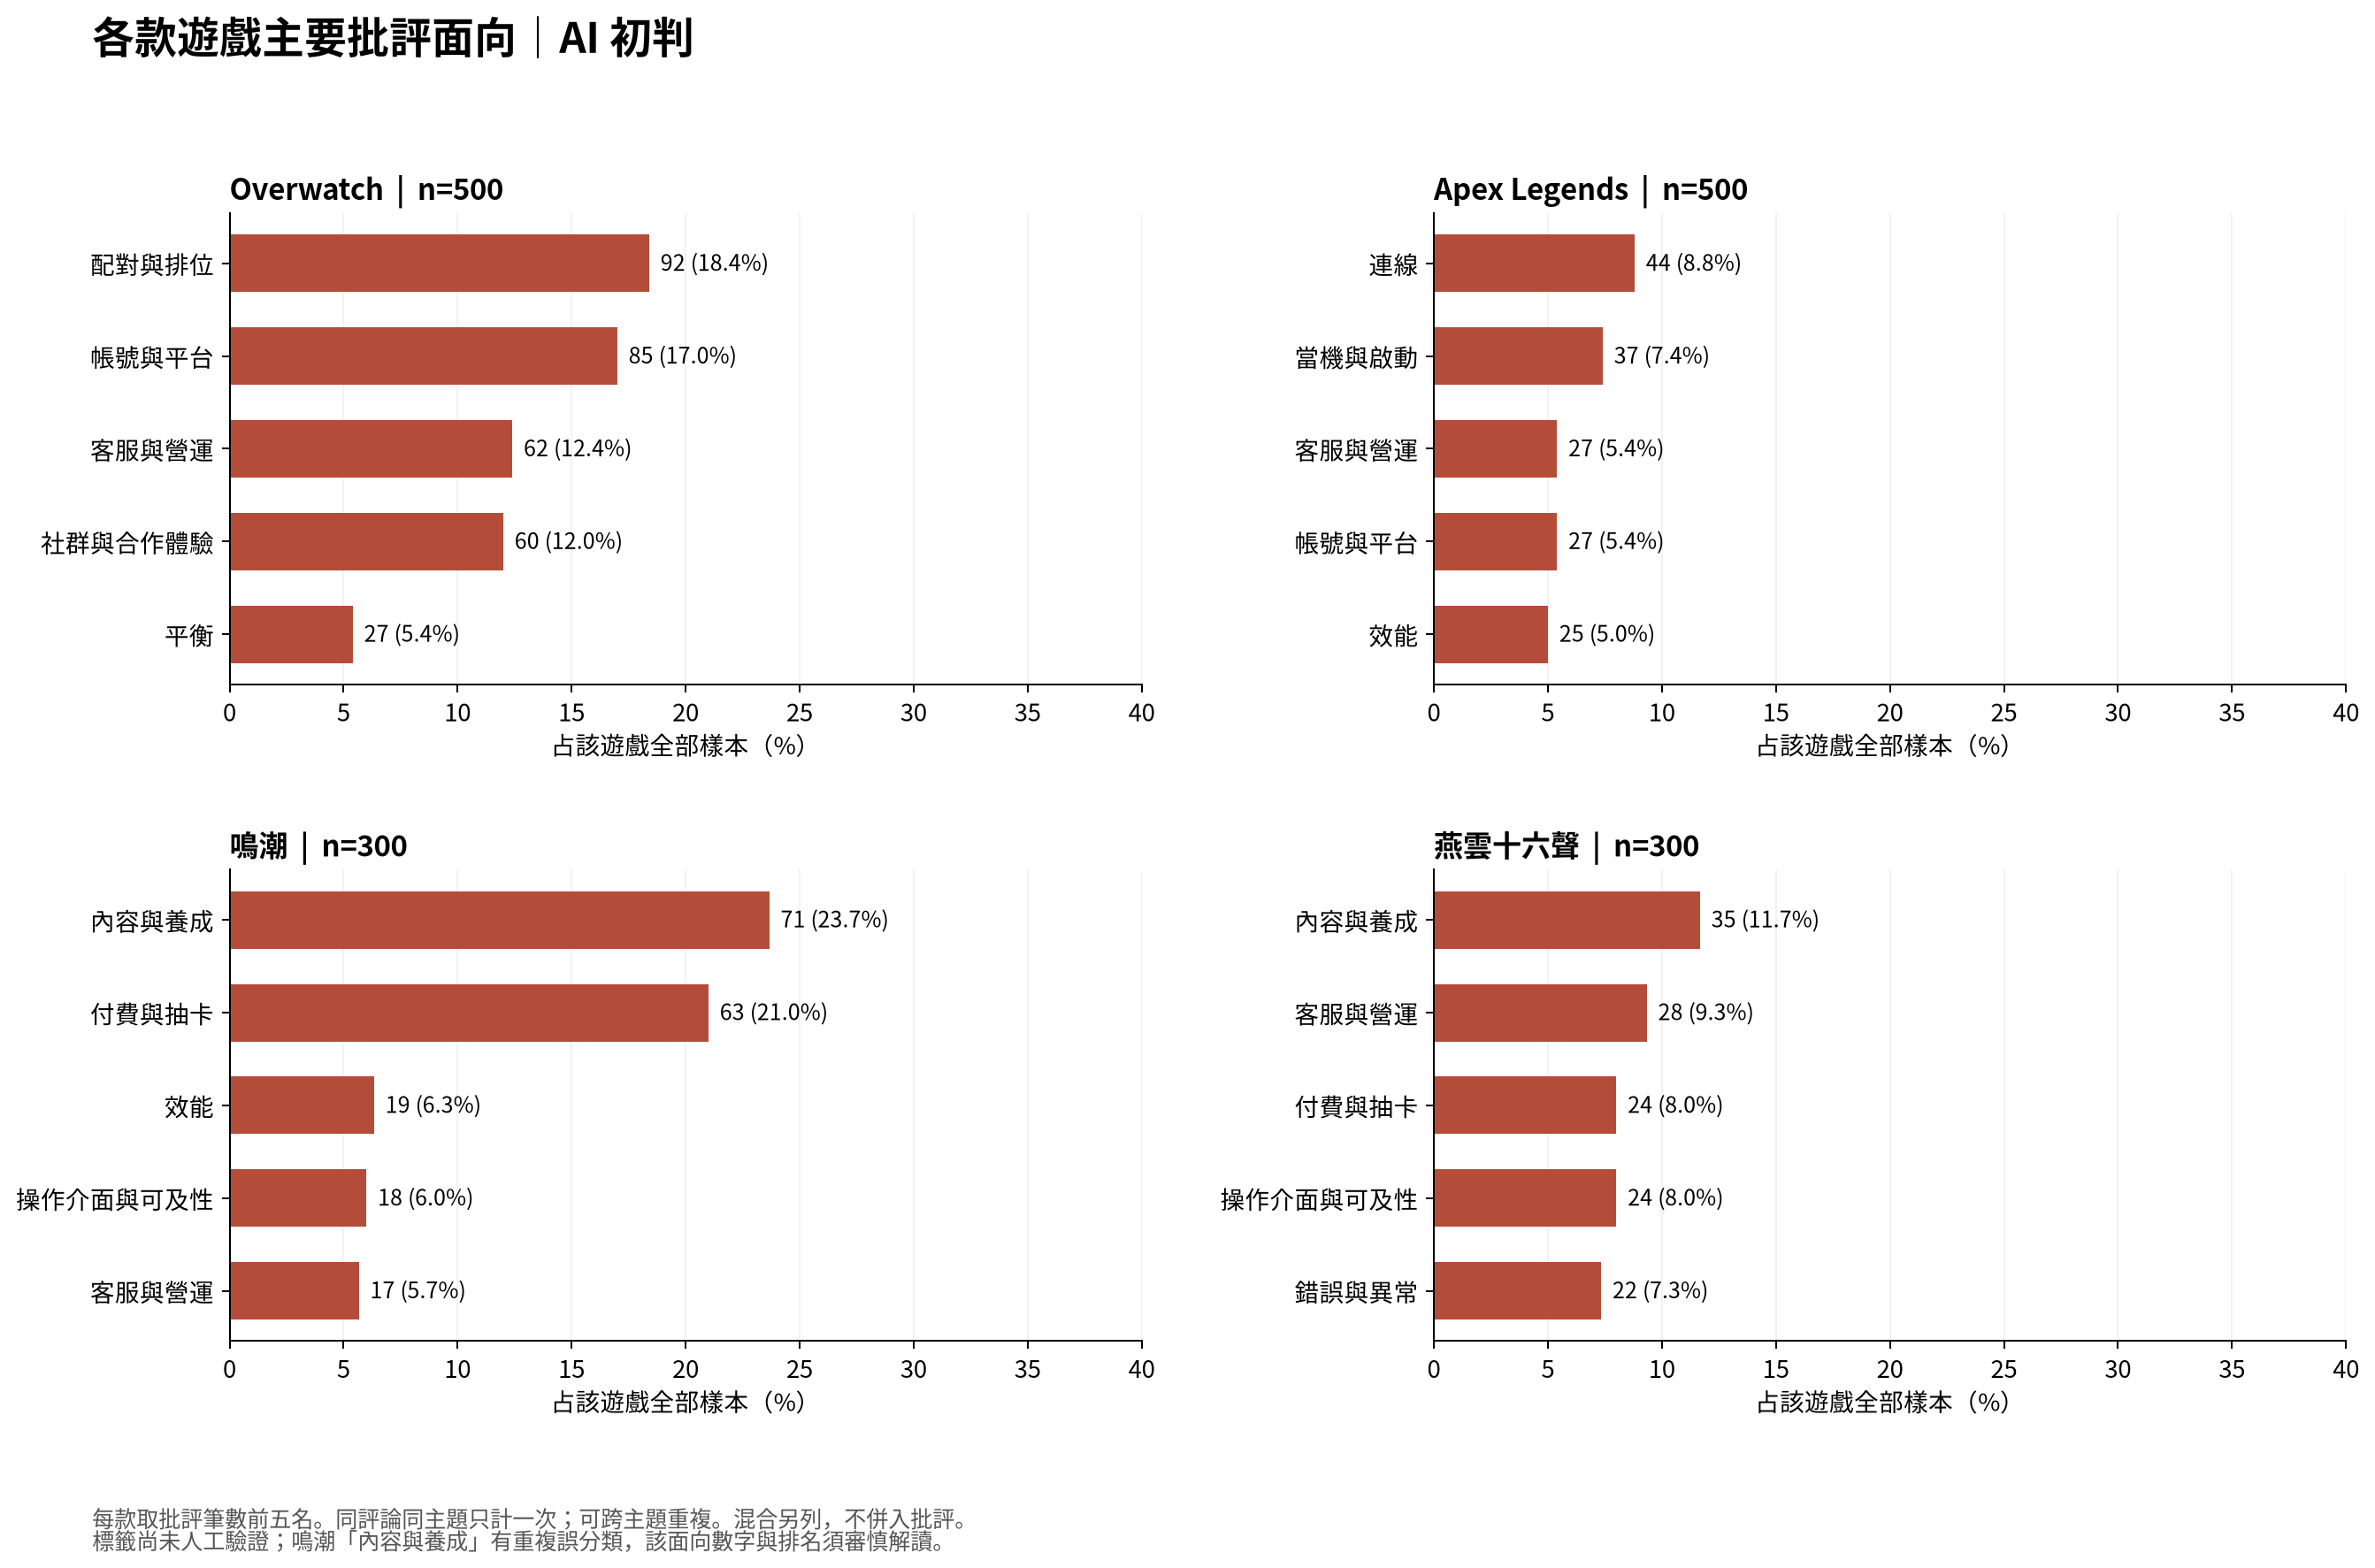

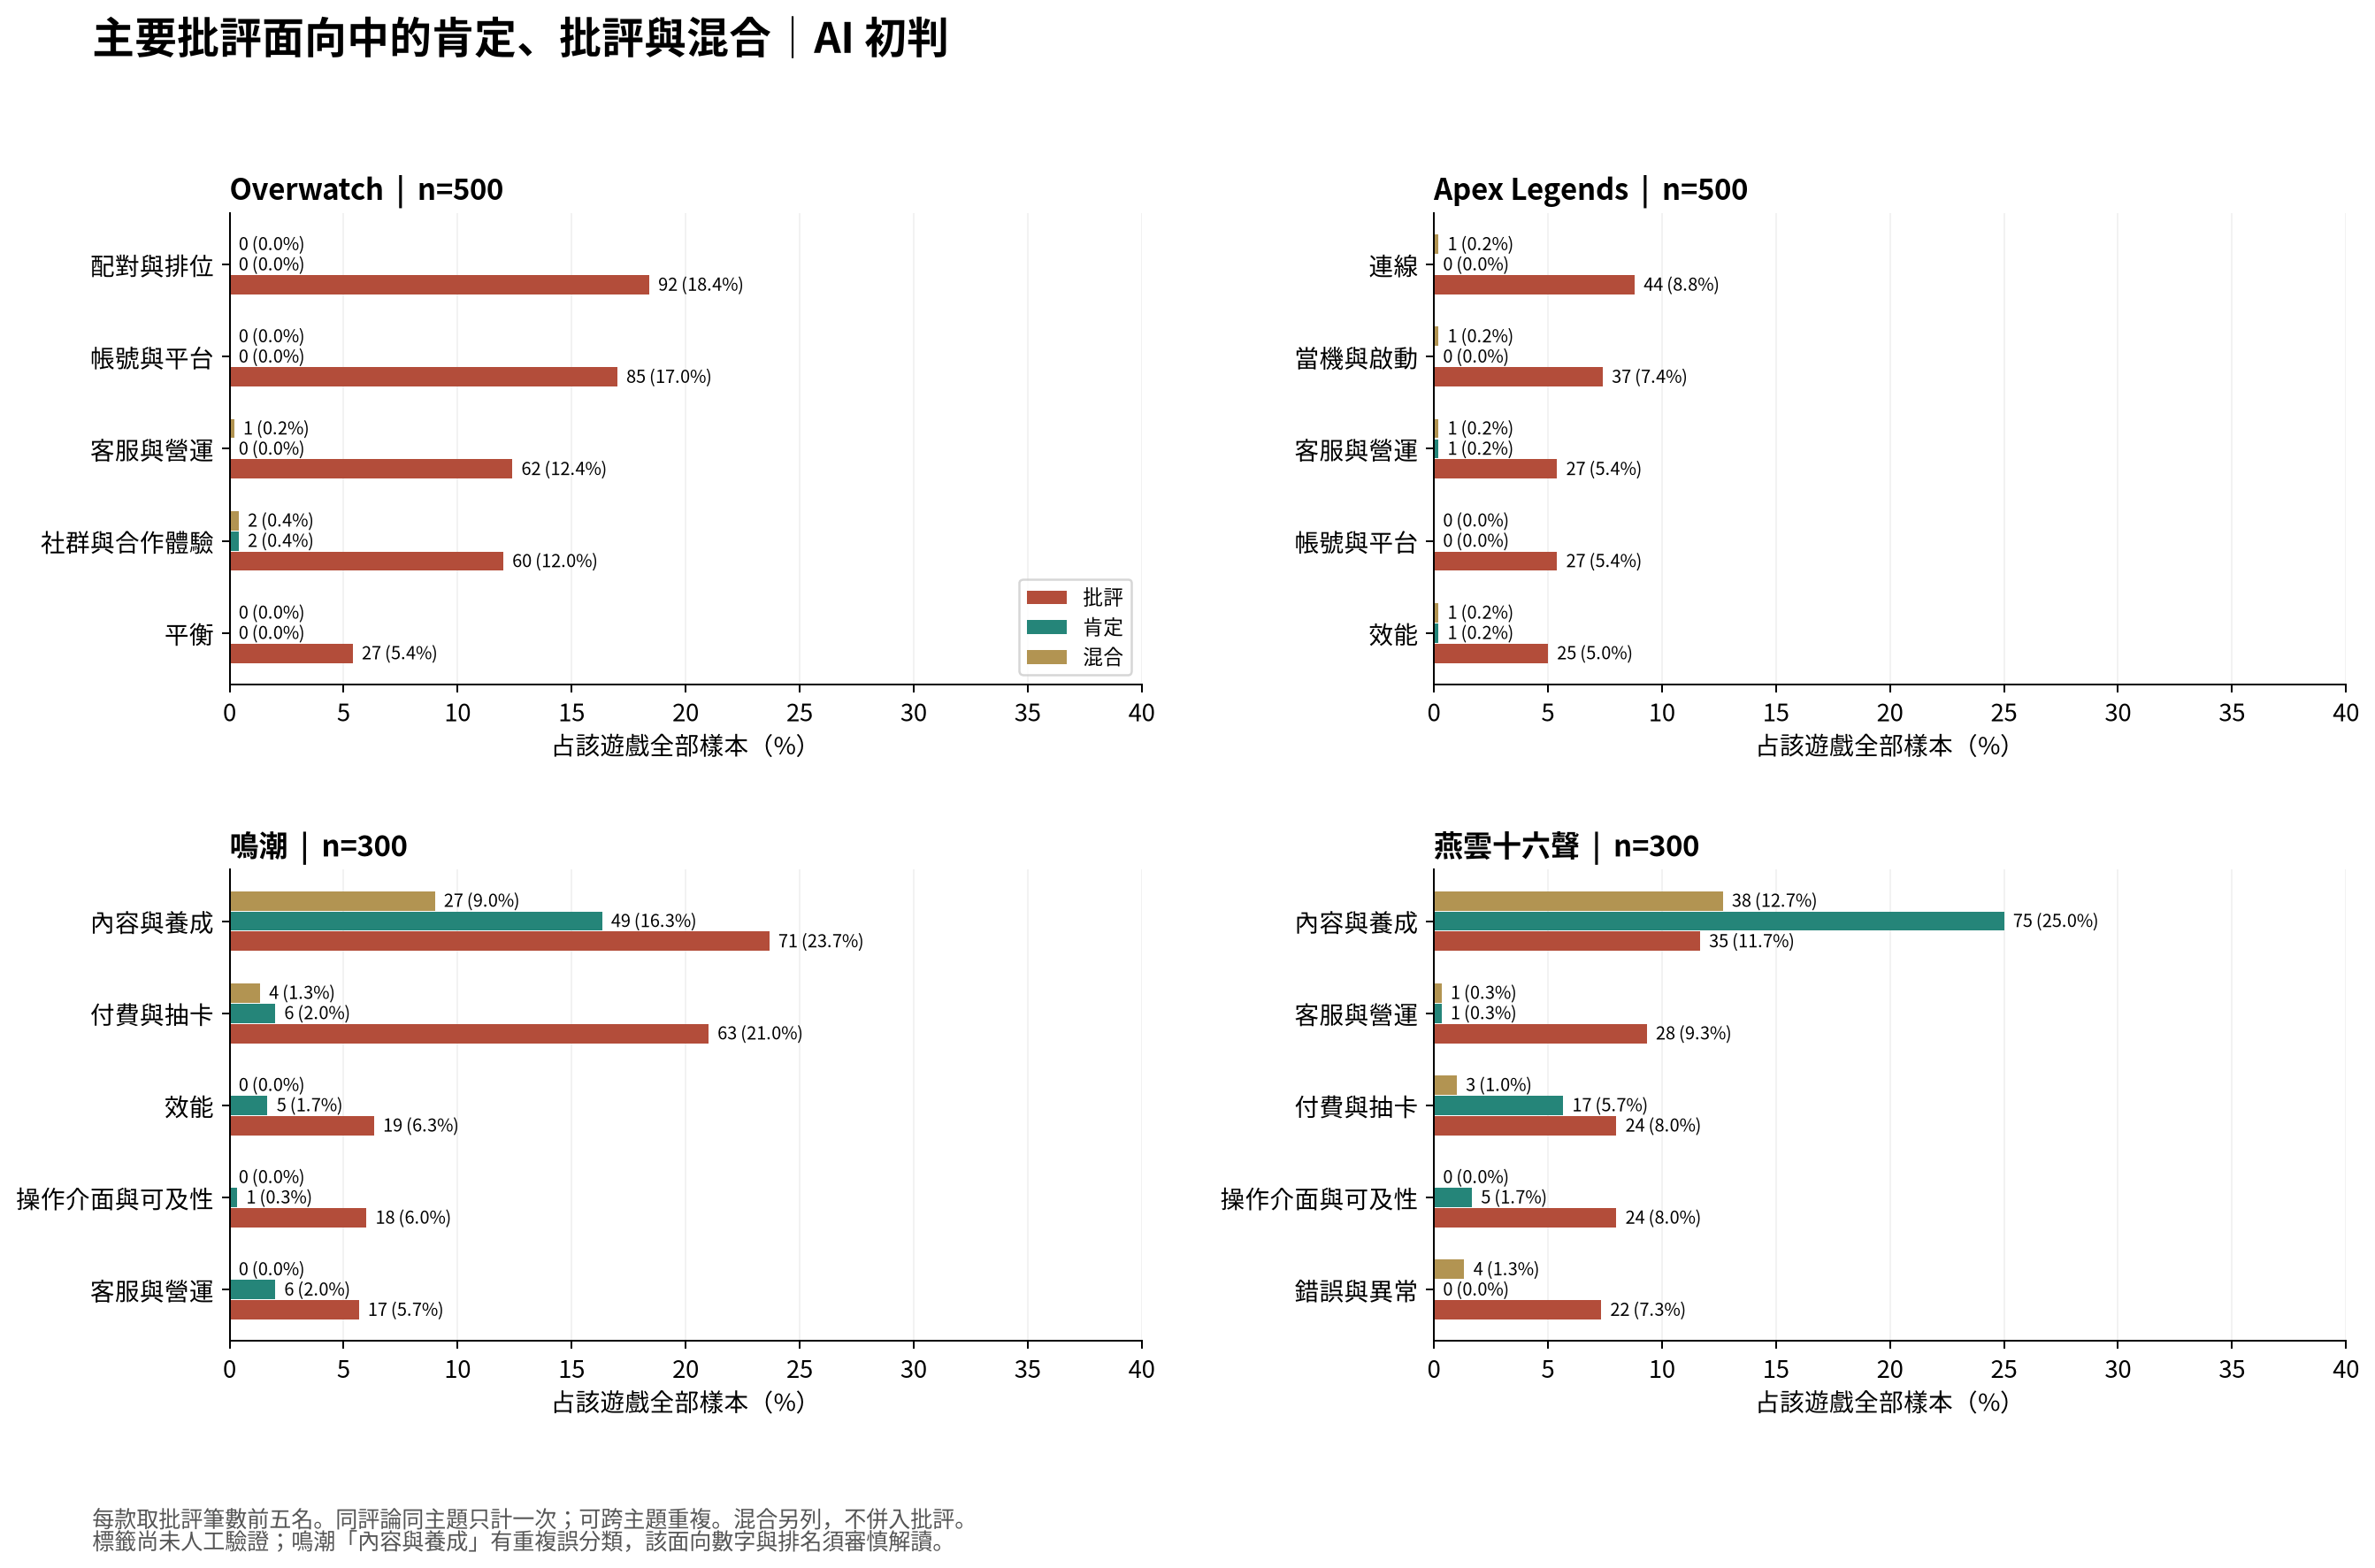

In [7]:
make_figures(stats, OUTPUT)
display(Image(filename=str(OUTPUT/'criticism.png')))
display(Image(filename=str(OUTPUT/'feedback.png')))


## 7. 原文抽查

主抽查共 24 個紀錄：各款前兩大批評面向，各三則；review_id 穩定排序，每組 random_state=42。鳴潮內容面向補抽十則，排除原三則後 random_state=43。補抽是分類品質抽查，不是重新抽研究樣本。不得據此計細項占比或分類準確率。

In [8]:
checks = export_review(df, long, stats, REVIEW_NOTES, OUTPUT)
display(checks[['抽查階段','game','目標主題','review_id','AI_主題態度','具體問題_助理摘要','助理抽查結果','原文證據','人工確認結果']])
print('主要抽查：', (checks['抽查階段']=='主要抽查').sum(), '補充：', (checks['抽查階段']=='補充抽查').sum())
print('人工欄留白；原始檔與 AI 標籤未修改。')


,抽查階段,game,目標主題,review_id,AI_主題態度,具體問題_助理摘要,助理抽查結果,原文證據,人工確認結果
0,主要抽查,Apex Legends,連線,237645911,連線：批評；當機與啟動：批評,朋友一晚掉線四次；另提反作弊，不能據此確認反作弊故障或因果。,支持,我朋友一晚上掉4回,
1,主要抽查,Apex Legends,連線,236465435,連線：批評,批評伺服器，未描述錯誤、時段、地區或重現步驟。,支持但缺乏細節,伺服器弄不好,
2,主要抽查,Apex Legends,連線,236529774,連線：批評,拼音疑指『伺服器是…』的辱罵，缺少具體連線現象；語意需確認。,可能支持；待使用者確認,fuwuqishishabi,
3,主要抽查,Apex Legends,當機與啟動,236531237,當機與啟動：批評；帳號與平台：批評,描述無法開啟遊戲，將原因歸於反作弊是玩家推測，未驗證。,支持,让所有玩家打不开游戏,
4,主要抽查,Apex Legends,當機與啟動,235316012,當機與啟動：批評,『研究怎麼進遊戲』暗示進入困難，也可能只是玩笑；無錯誤訊息。,可能支持；待使用者確認,研究怎么进游戏,
5,主要抽查,Apex Legends,當機與啟動,232961522,連線：批評；當機與啟動：批評,描述瞬移跳幀，以及反作弊後不能玩；未明確區分當機、踢出或啟動失敗。,部分支持；故障類型待確認,莫名其妙就自己死了，然后不让玩了,
6,主要抽查,Overwatch,配對與排位,234431993,配對與排位：批評；教學與引導：批評；社群與合作體驗：批評；美術與音樂：肯定,批評匹配並描述新玩家遭隊友辱罵；新手配對與社群問題需分開查證，另肯定玩法與畫風。,支持但涉及多面向,4把游戏，因为是萌新在熟悉游戏而被队友骂了3把,
7,主要抽查,Overwatch,配對與排位,233026072,配對與排位：批評；平衡：批評,直接批評匹配機制與坦克平衡；個人表現仍輸的描述不足以證明匹配不公平。,支持,两大不好，匹配机制，t位英雄数值平衡,
8,主要抽查,Overwatch,配對與排位,235765547,配對與排位：批評；社群與合作體驗：批評,批評匹配與隊友，未提供段位差、模式或對局資料。,支持但缺乏細節,匹配机制烂到极致,
9,主要抽查,Overwatch,帳號與平台,238088070,帳號與平台：批評；社群與合作體驗：批評；客服與營運：批評,榮譽等級限制聊天，較貼近社群治理／溝通權限；未描述帳號登入或平台驗證問題。,主題邊界待確認,榮譽等級一不能說話,


主要抽查： 24 補充： 10
人工欄留白；原始檔與 AI 標籤未修改。


## 8. 成果報告、摘要與證據

目的選例與額外標籤疑點獨立保存，不混入隨機抽查。建議是下一步蒐證方向；整面向筆數不能充作具體問題筆數。

In [9]:
export_extra_evidence(df, OUTPUT)
summary = build_report(df, stats, top5, positive, emotions, sensitivity, validation, checks, OUTPUT)
display(summary)
display(Markdown((OUTPUT/'README_summary.md').read_text(encoding='utf-8')))
display(Markdown((OUTPUT/'analysis_report.md').read_text(encoding='utf-8')))


,遊戲,優先調查事項,對應面向數據_AI初判,原文證據,下一個查證動作,解讀界線
0,Overwatch,新玩家配對體驗與溝通環境,92／500（18.4%）,234431993：「4把游戏，因为是萌新在熟悉游戏而被队友骂了3把」；另有 2330260...,依新玩家／模式／地區／段位差分層，查對局分差、勝負差距、組隊狀態、聊天檢舉與前幾場體驗；核對...,92 則是整個配對與排位面向，並非 92 則新手受辱，也未證明演算法不公平。
1,Apex Legends,掉線與重新連線流程,44／500（8.8%）,237645911：「我朋友一晚上掉4回」；236465435 批評伺服器但無重現細節。,先收時段、伺服器區域、網路供應商、錯誤碼與斷線紀錄；重現斷線→重連→排位處罰流程，核對伺服器...,44 則並非全都回報掉線；不能由評論認定伺服器根因或反作弊因果。
2,鳴潮,抽卡保底成本與機制理解,63／300（21.0%）,238133779：「不优化卡池的话，那就差评」；231793305：「抽卡昂貴」。,分開查保底規則理解、付費成本感受與抽取紀錄；測試卡池說明、保底進度與成本呈現是否易懂，機率異...,不採用受污染的內容與養成排名推導具體內容缺陷；不把月卡後歪卡視為機率改變。
3,燕雲十六聲,更新內容與養成材料解鎖時程銜接,28／300（9.3%）,233270638：「奇術突破材料要到新地圖拿新地圖要等全服共建」；233258748 另提...,核對更新／共建／地圖與材料開放時間；用不同進度帳號測試取得新奇術後能否升級、介面是否清楚說明...,28 則屬整個客服與營運面向，不能視為 28 則材料解鎖問題；原文未證明實際規則或缺陷。


## Steam 中文玩家體驗分析｜階段成果

**AI 初判統計，尚待人工複核。** 研究使用 2026/08/01–2026/10/31（台灣時間）建立的 1,600 則 Steam 繁簡中文評論：Overwatch 500、Apex Legends 500、鳴潮 300、燕雲十六聲 300。樣本配額、評論 ID 唯一性與建立日期檢查通過；9 則原文於研究期後更新。

以「評論 × 主題」計數，同評論同主題只計一次，各主題占比以該款全部樣本為分母；「混合」另列，不併入批評。多主題占比可超過 100%。

- Overwatch：配對與排位批評 92／500（18.4%），帳號與平台 85／500（17.0%）。優先蒐證新玩家的配對落差與溝通環境。
- Apex Legends：連線批評 44／500（8.8%），當機與啟動 37／500（7.4%）。優先蒐證掉線、重連及處罰流程。
- 鳴潮：付費與抽卡批評 63／300（21.0%），優先查保底規則理解與成本感受。「內容與養成」原標 71／300（23.7%）有反覆誤分類，暫不據此推導內容問題排名。
- 燕雲十六聲：內容與養成批評 35／300（11.7%），客服與營運 28／300（9.3%）；內容面向也有肯定 75／300（25.0%）、混合 38／300（12.7%）。優先查更新內容與材料解鎖時程的銜接。

助理抽查 24 個評論×主題案例，並對鳴潮內容面向補查 10 則。這是 AI 助理再次閱讀原文，未冒充人工驗證；原標籤保留，人工確認欄留白。另見肯定標籤誤判，正反比例均需人工確認。細項比例須等完整標記後再算。

正面案例包含 Apex 戰鬥手感、Overwatch 新模式、燕雲路線規劃與鳴潮畫面表現；案例不代表整體比例。建議皆為下一步調查事項，修復排序需結合營運資料與 QA 重現。結論僅限本樣本，不代表所有平台或所有玩家。

# Steam 中文玩家體驗分析｜v0.2 工作包成果

**狀態：AI 初判統計＋助理原文抽查；尚未完成人工驗證。** 原始資料與標籤保持不變。

## 研究問題與範圍

各款評論者肯定／批評哪些體驗，以及營運團隊可先查什麼？本版使用使用者提供的 1,600 則樣本：Overwatch 500、Apex Legends 500、鳴潮 300、燕雲十六聲 300。建立時間限定台灣時間 2026/08/01–2026/10/31。語言是 Steam 繁簡中文標記，不保證原文全為中文。未重新抽樣、未做時數分組或機器學習；平均時數圖不納入主要結論。

## 驗證結果

- 1,600 列、35 欄；配額與 App ID 相符，評論 ID 全部唯一；必要分析欄無缺值，原文無空白。人工確認欄留白屬預期。
- 建立時間：2026-08-01 05:26:12+08:00 至 2026-10-31 23:37:07+08:00；月份與台灣時間一致。
- 同遊戲同文字但不同評論 ID 共 133 列額外重複，保留，不以文字去重。檔案本身不能證明帳號獨立性或來源真實性。
- 9 則評論於研究期後更新（Overwatch 4、Apex 1、鳴潮 2、燕雲 2）；只有收集時原文，無法還原研究期末版本。主分析保留，另附排除這九則的敏感度表。
- 分析適用性：921 則可作產品語意分析、564 則僅情緒／語氣參考、115 則無法判讀產品體驗。679 則無具體主題；主題占比仍以各款全部樣本為分母。
- 原始人工狀態全為未驗證。來源 SHA-256：`05cfe2fda17b17fcabc18d71d686fba53058ac9906f94b1a9ade3a34e142e088`。

## 計數方法

解析「各主題態度_AI」，核對其主題集合與「主題_AI」一致。每個遊戲＋評論 ID＋主題只計一次；態度衝突會停止。批評只計「批評」，肯定只計「肯定」；「混合」「中性提及」「不確定」另列，不把整體負面情緒或 Steam 不推薦推成每個主題都負面。
占比＝該款符合目標態度的評論×主題筆數／該款全部樣本。跨主題可重複，總和可能超過 100%；不以有效資訊數或批評評論數改分母，不合併四款推論市場。前五名按筆數遞減，同筆數按主題字串排序。

## 主要批評面向

![各款遊戲主要批評面向](criticism.png)

| 遊戲 | 批評面向_AI | 筆數 | 占該遊戲全部樣本 |
| --- | --- | --- | --- |
| Apex Legends | 連線 | 44 | 8.8% |
| Apex Legends | 當機與啟動 | 37 | 7.4% |
| Apex Legends | 客服與營運 | 27 | 5.4% |
| Apex Legends | 帳號與平台 | 27 | 5.4% |
| Apex Legends | 效能 | 25 | 5.0% |
| Overwatch | 配對與排位 | 92 | 18.4% |
| Overwatch | 帳號與平台 | 85 | 17.0% |
| Overwatch | 客服與營運 | 62 | 12.4% |
| Overwatch | 社群與合作體驗 | 60 | 12.0% |
| Overwatch | 平衡 | 27 | 5.4% |
| 燕雲十六聲 | 內容與養成 | 35 | 11.7% |
| 燕雲十六聲 | 客服與營運 | 28 | 9.3% |
| 燕雲十六聲 | 付費與抽卡 | 24 | 8.0% |
| 燕雲十六聲 | 操作介面與可及性 | 24 | 8.0% |
| 燕雲十六聲 | 錯誤與異常 | 22 | 7.3% |
| 鳴潮 | 內容與養成 | 71 | 23.7% |
| 鳴潮 | 付費與抽卡 | 63 | 21.0% |
| 鳴潮 | 效能 | 19 | 6.3% |
| 鳴潮 | 操作介面與可及性 | 18 | 6.0% |
| 鳴潮 | 客服與營運 | 17 | 5.7% |

**鳴潮「內容與養成」71 則／23.7% 是原 AI 標籤統計，已發現反覆誤分類，不能據此認定內容問題最多。所有主題數字仍是待人工驗證的描述。**

## 肯定與批評並列

![同面向各種回饋](feedback.png)

燕雲十六聲「內容與養成」有肯定 75／300（25.0%）、批評 35／300（11.7%）、混合 38／300（12.7%）；不能單以批評面向排名描述整體口碑。鳴潮同面向肯定 49／300（16.3%）、批評 71／300（23.7%）、混合 27／300（9.0%），但其標籤邊界有問題，兩側比例都需複核。

各款 AI 肯定面向前五名如下；只列明確的主題肯定，不把籠統「好玩」補成玩法或內容。

| 遊戲 | 肯定面向_AI | 筆數 | 占該遊戲全部樣本 |
| --- | --- | --- | --- |
| Apex Legends | 操作與戰鬥 | 15 | 3.0% |
| Apex Legends | 內容與養成 | 10 | 2.0% |
| Apex Legends | 美術與音樂 | 4 | 0.8% |
| Apex Legends | 社群與合作體驗 | 3 | 0.6% |
| Apex Legends | 付費與抽卡 | 2 | 0.4% |
| Overwatch | 內容與養成 | 7 | 1.4% |
| Overwatch | 美術與音樂 | 6 | 1.2% |
| Overwatch | 操作與戰鬥 | 4 | 0.8% |
| Overwatch | 付費與抽卡 | 2 | 0.4% |
| Overwatch | 效能 | 2 | 0.4% |
| 燕雲十六聲 | 內容與養成 | 75 | 25.0% |
| 燕雲十六聲 | 美術與音樂 | 51 | 17.0% |
| 燕雲十六聲 | 操作與戰鬥 | 28 | 9.3% |
| 燕雲十六聲 | 付費與抽卡 | 17 | 5.7% |
| 燕雲十六聲 | 社群與合作體驗 | 7 | 2.3% |
| 鳴潮 | 美術與音樂 | 57 | 19.0% |
| 鳴潮 | 內容與養成 | 49 | 16.3% |
| 鳴潮 | 操作與戰鬥 | 11 | 3.7% |
| 鳴潮 | 付費與抽卡 | 6 | 2.0% |
| 鳴潮 | 客服與營運 | 6 | 2.0% |

可支持肯定的具體案例（目的選例，另於 evidence_examples.csv 保留全文，不屬 24 筆隨機抽查）：Apex 237431132「战斗爽」；Overwatch 237241641 喜歡新模式並希望常駐；燕雲 232274254 描述自行規劃採藥路線與轉乘；鳴潮 232285054 描述高畫質設備下的畫面優勢。這些案例不代表整個主題所有評論。

## 原文抽查與標籤限制

每款前兩大批評面向，各抽三則，共 24 個抽查紀錄。各組先按 review_id 排序，以種子 42 抽取；同評論可出現在不同面向。本次讀原文者仍是 AI 助理，新增助理摘要／結果並留白人工確認欄，不能稱為人工驗證或分類準確率驗收。完整原文見 review_check.md 與 CSV。
- Apex 連線案例中有明確掉線描述，也有只有辱罵或拼音的短句；啟動面向有進入困難，但部分未分清當機、踢出或反作弊限制。
- Overwatch 配對三則支持玩家不滿，但不能驗證公平性；帳號面向的榮譽等級聊天限制存在主題邊界疑問，不能都當登入或驗證問題。
- 燕雲內容面向有世界等級與主線難度案例，但第三章比較缺細節，衣服外觀較貼近美術／自訂。營運案例支持查更新時程及活動設計，不代表客服失效。
- 鳴潮內容與養成主抽三則中，兩則分別只談技能說明與抽卡，沒有支持目標主題；另一則疑為反諷。因反覆不符，排除原三則後以種子 43 補抽十則，其中六則只談抽卡／中獎、兩則資訊不足，另兩則分別涉及聲骸與角色敘事。這是抽查紀錄，**不能外推誤判率，也不能直接扣減全體 71 則**。
- 額外檢視肯定案例時，Overwatch 231976333 明確批評新模式，卻被標「內容與養成：肯定」；燕雲 234215648「風景沒話說」不足以獨立支持內容養成肯定。肯定比例亦不能視為人工確認結果；問題記錄另列，不混入隨機抽查。
後續完整複核應先明訂內容／養成、抽卡、介面／教學、社群治理的邊界，逐則記錄修正理由與人工確認欄，之後再重算排名。現階段不計算「掉線」「材料解鎖」「新手受辱」等細項比例。

## 每款一項優先調查事項

| 遊戲 | 優先調查事項 | 對應面向數據_AI初判 | 原文證據 | 下一個查證動作 | 解讀界線 |
| --- | --- | --- | --- | --- | --- |
| Overwatch | 新玩家配對體驗與溝通環境 | 92／500（18.4%） | 234431993：「4把游戏，因为是萌新在熟悉游戏而被队友骂了3把」；另有 233026072、235765547 直接批評匹配。 | 依新玩家／模式／地區／段位差分層，查對局分差、勝負差距、組隊狀態、聊天檢舉與前幾場體驗；核對是配對落差還是社群互動。 | 92 則是整個配對與排位面向，並非 92 則新手受辱，也未證明演算法不公平。 |
| Apex Legends | 掉線與重新連線流程 | 44／500（8.8%） | 237645911：「我朋友一晚上掉4回」；236465435 批評伺服器但無重現細節。 | 先收時段、伺服器區域、網路供應商、錯誤碼與斷線紀錄；重現斷線→重連→排位處罰流程，核對伺服器與客戶端日誌。 | 44 則並非全都回報掉線；不能由評論認定伺服器根因或反作弊因果。 |
| 鳴潮 | 抽卡保底成本與機制理解 | 63／300（21.0%） | 238133779：「不优化卡池的话，那就差评」；231793305：「抽卡昂貴」。 | 分開查保底規則理解、付費成本感受與抽取紀錄；測試卡池說明、保底進度與成本呈現是否易懂，機率異常須由實際日誌另驗。 | 不採用受污染的內容與養成排名推導具體內容缺陷；不把月卡後歪卡視為機率改變。 |
| 燕雲十六聲 | 更新內容與養成材料解鎖時程銜接 | 28／300（9.3%） | 233270638：「奇術突破材料要到新地圖拿新地圖要等全服共建」；233258748 另提更新品質與活動冗長。 | 核對更新／共建／地圖與材料開放時間；用不同進度帳號測試取得新奇術後能否升級、介面是否清楚說明門檻與預期開放時間。 | 28 則屬整個客服與營運面向，不能視為 28 則材料解鎖問題；原文未證明實際規則或缺陷。 |

以上是優先蒐證方向，並非修復排序。評論能指出問題線索，不能直接證明 Bug、嚴重程度、流失原因或營收影響。

## 研究期後更新敏感度

排除研究期後更新評論時，分母同步改為 Overwatch 496、Apex 499、鳴潮 298、燕雲 298；保留同一計數方法。完整結果見 sensitivity_excluding_post_period_updates.csv。此檢查不能還原舊原文，也不取代主要樣本。

## 檔案與重現

- `Steam_Experience_Analysis_v02.ipynb`：已執行並保留輸出；Colab 可上傳同名 CSV，其他檔名可填 INPUT_PATH。
- `analysis.py`、`review_notes.json`：分析函式與可稽核的助理抽查註記。
- `review_topic_long.csv`、`topic_statistics_AI.csv`、`top5_criticism_AI.csv`、`top5_praise_AI.csv`：完整計數及占比。
- `review_check_24.csv`、`review_check_supplement_10.csv`、`review_check_all_34.csv`、`review_check.md`：抽查紀錄，人工欄留白。
- `investigation_summary.csv`、`README_summary.md`：優先調查摘要與可貼入 GitHub 的文字。
- `criticism`／`feedback`：PNG、SVG、PDF 圖檔；資料標註 AI 初判。
- `evidence_examples.csv` 與 `additional_label_issues.csv`：目的選取的肯定案例及額外標籤疑點。
- `validation.json`、`sample_composition.csv`、`emotion_statistics_AI.csv`：品質、組成及整體情緒（與主題態度分開）。

尚未驗證抽樣母體、抽樣過程、來源介面或標籤產生流程，亦未同步 Google Drive 或修改原始 CSV。研究結論僅限指定樣本。

## 9. 匯出成果

執行後產生結果 ZIP；Colab 可取消註解下載。Notebook 本身請另外透過 Colab「檔案 → 下載 → .ipynb」保留程式與輸出。CSV 為 UTF-8 BOM，便於 Excel 開啟；沒有修改或覆蓋原始資料。

In [10]:
import shutil
archive = shutil.make_archive('steam_analysis_results_v02', 'zip', OUTPUT)
print('成果 ZIP：', archive)
print('輸出檔：')
for path in sorted(OUTPUT.iterdir()):
    print(path.name)
# Colab 下載：
# from google.colab import files
# files.download(archive)


成果 ZIP： /workspace/steam_analysis_v02/steam_analysis_results_v02.zip
輸出檔：
README_summary.md
additional_label_issues.csv
analysis_report.md
criticism.pdf
criticism.png
criticism.svg
emotion_statistics_AI.csv
evidence_examples.csv
feedback.pdf
feedback.png
feedback.svg
investigation_summary.csv
review_check.md
review_check_24.csv
review_check_all_34.csv
review_check_supplement_10.csv
review_topic_long.csv
sample_composition.csv
sensitivity_excluding_post_period_updates.csv
top5_criticism_AI.csv
top5_praise_AI.csv
topic_statistics_AI.csv
validation.json
